# armorCache

armorCache is a python script dedicated to pulling market values off of TornCity's item market using API calls to determine profitability in regards to opening armor caches.

Armor Caches are a type of lootbox where a random drop will be rolled each time you open one. It is assumed to be I.I.D. and odds for each pull are published https://www.torn.com/rules.php#tab=odds_disclosure

The objective is to determine the Expected Value of a singular armor cache and to simulate long term behavior and whether or not it can be economically viable to open armor caches at a given price of the cache itself and the prices of the potential outcomes.

The gambler's ruin is also applied to determine how likely it is to attain a target cash value or go bankrupt. 

### Notes and limitations: 

There are a select amount of items where the best way to sell them is to convert them into "Bunker Bucks" by exchanging it with the NPC shop. These items are manually selected due to their overall poor quality but this list is subject to change should a shift in their viability occur (but is extremely unlikely). The value of an individual "Bunker Buck" is calculated automatically and assumes the user trades their "Bucnker Bucks" optimally.

In addition, each individual armor rolls a random value for the bonus% and armor%. A high bonus% and armor% roll will sell far beyond the lowest price, however the rates of these are unknown so we assume a worst case scenario of the worst bonus and armor % so the armor is sold at the lowest market price. 

### Next Goals:

Implement Price History Tracking. Anecdotally, prices for caches fluctuate throughout the week and have a weekly peak/low due to how they are circulated (ranked wars that introduce new caches into the market typically end Saturday-Monday so there are usually more caches in circulation around that time). Introducing a price history to figure out when to buy caches and when to sell the drops for maximum profit could lead to a significant change in EV and simulation results. 

In [150]:
import requests

API_KEY = "O5vs2Di6GfeuLV67"

def fetch_item_market(item_id, limit=20, offset=0):
    url = f"https://api.torn.com/v2/market/{item_id}/itemmarket"
    params = {
        "limit": limit,
        "offset": offset,
        "key": API_KEY
    }
    r = requests.get(url, params=params)
    r.raise_for_status()
    return r.json()

In [132]:
def get_item_price(item_id):
    data = fetch_item_market(item_id)
    listings = data["itemmarket"]["listings"]
    return min(l["price"] for l in listings)

In [133]:
# Construct the armorCache dictionary with item IDs and probabilities
armorCache = {
    'cost': get_item_price(1118),
    'drops': [
        {"itemID": 680, "prob":0.002},
        {"itemID": 681, "prob":0.002},
        {"itemID": 682, "prob":0.002},
        {"itemID": 683, "prob":0.002},
        {"itemID": 684, "prob":0.002},
        {"itemID": 1355, "prob":0.0045},
        {"itemID": 1356, "prob":0.0045},
        {"itemID": 1357, "prob":0.0045},
        {"itemID": 1358, "prob":0.0045},
        {"itemID": 1359, "prob":0.0045},
        {"itemID": 670, "prob":0.0045},
        {"itemID": 671, "prob":0.0045},
        {"itemID": 672, "prob":0.0045},
        {"itemID": 673, "prob":0.0045},
        {"itemID": 674, "prob":0.0045},
        {"itemID": 1307, "prob":0.0045},
        {"itemID": 1308, "prob":0.0045},
        {"itemID": 1309, "prob":0.0045},
        {"itemID": 1310, "prob":0.0045},
        {"itemID": 1311, "prob":0.0045},
        {"itemID": 675, "prob":0.0045},
        {"itemID": 676, "prob":0.0045},
        {"itemID": 677, "prob":0.0045},
        {"itemID": 678, "prob":0.0045},
        {"itemID": 679, "prob":0.0045},
        {"itemID": 665, "prob":0.06},
        {"itemID": 666, "prob":0.06},
        {"itemID": 667, "prob":0.06},
        {"itemID": 668, "prob":0.06},
        {"itemID": 669, "prob":0.06},
        {"itemID": 655, "prob":0.06},
    ]
}

In [134]:
# Propagate the prices for each drop
for drop in armorCache['drops']:
    drop['price'] = get_item_price(drop['itemID'])
    drop['item'] = fetch_item_market(drop['itemID'])['itemmarket']['item']['name']


In [135]:
# Obtain the prices for other caches for BB calculation
cachePrices = {
    'armor' : [{"price": armorCache['cost'], "BBCost": 60}],
    'melee' : [{"price": get_item_price(1119), "BBCost": 30}],
    'smallArms' : [{"price": get_item_price(1120), "BBCost": 20}],
    'mediumArms'  : [{"price": get_item_price(1121), "BBCost": 50}],
    'heavyArms' : [{"price" : get_item_price(1122), "BBCost": 70}],
}

# Calculate the best BB value
BBValue = 0
bestValue = 0
for cacheType, cacheData in cachePrices.items():
    for cache in cacheData:
        currentValue = cache['price']/cache['BBCost']
        if currentValue > bestValue:
            bestValue = currentValue
            BBValue = cache['price']/cache['BBCost']

In [136]:
# Append the Bunker Bucks drop to the armorCache dictionary (9999 is a placeholder itemID for Bunker Bucks)
armorCache['drops'].append({"itemID": 9999, "prob":0.54, "price": BBValue, "item": "Bunker Bucks"})

In [137]:
# Calculate EV and variance for armor caches
armorCacheEV = 0 - armorCache['cost']
for drop in armorCache['drops']:
    armorCacheEV += drop['prob'] * (drop['price']) * 0.95 # Applying 5% sales tax
print("Armor Cache EV:", armorCacheEV)

armorCacheVariance = 0
for drop in armorCache['drops']:
    armorCacheVariance += drop['prob'] * ((drop['price'] * 0.95) - armorCacheEV) ** 2
print("Armor Cache Variance:", armorCacheVariance)

Armor Cache EV: -41260697.66654999
Armor Cache Variance: 1.1660251307566979e+18


In [138]:
import random

# Opens one armor cache and returns the item and its value after tax
def open_once(armorCache):
    r = random.random()
    cumulative = 0

    for d in armorCache["drops"]:
        cumulative += d["prob"]
        if r <= cumulative:
            return d["item"], d["price"]*0.95


In [139]:
# Helper function to simulate multiple openings of the armor cache
def gamble(armorCache, times=10):
    total_cost = armorCache['cost'] * times
    total_value = 0
    itemList = []
    for _ in range(times):
        item, price = open_once(armorCache)
        total_value += price
        itemList.append(item)
    count = {}
    for item in set(itemList):
        count[item] = itemList.count(item)
    return total_value - total_cost, (total_value - total_cost) > 0, count

In [140]:
# Simulates n1 trials of opening n2 armor caches and reports the profit rate and average profit per trial
from collections import Counter

def simulate(armorCache, trials=1000, times=10):
    wins = 0
    total_profit = 0
    item_summary = Counter()
    for _ in range(trials):
        profit, won, items = gamble(armorCache, times)
        total_profit += profit
        item_summary.update(items)
        if won:
            wins += 1
    return item_summary, trials, times, wins, total_profit

After 10000 trials of opening 100 Armor Caches:
Profit Rate: 31.74%
Average Profit per Trial: -4068310036.86


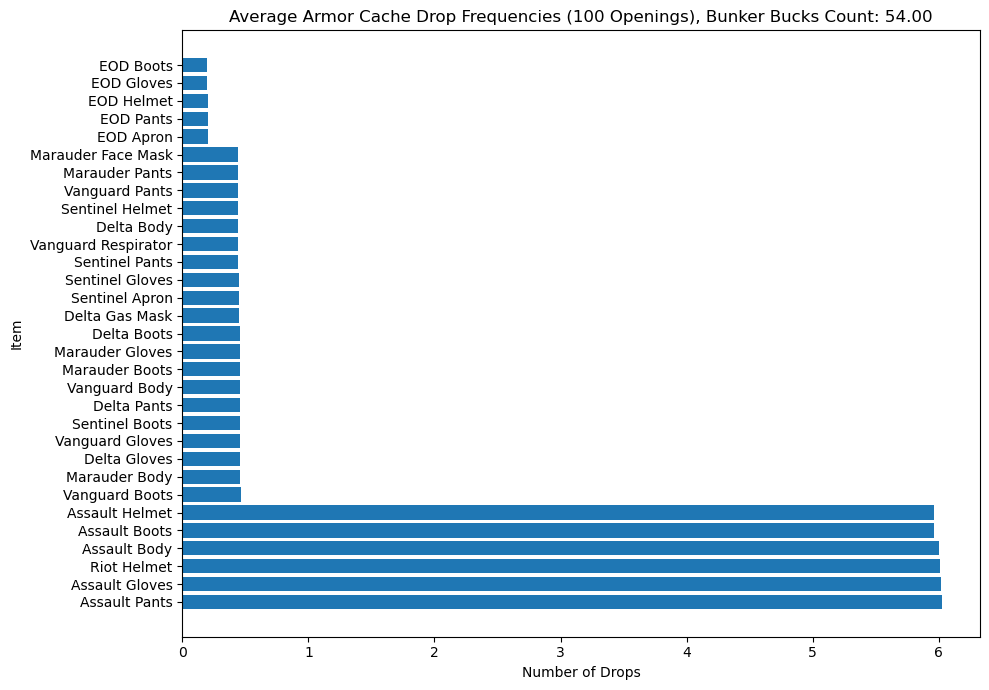

In [ ]:
item_summary, trials, times, wins, total_profit = simulate(armorCache, trials=10000, times=100)
items = sorted(item_summary.items(), key=lambda x: x[1], reverse=True)
bbcount = item_summary['Bunker Bucks']
items.remove(('Bunker Bucks', item_summary['Bunker Bucks']))  # Remove Bunker Bucks from the list for plotting
names = [item[0] for item in items]
counts = [item[1] for item in items]
counts = [x / 10000 for x in counts]
print(f"After {trials} trials of opening {times} Armor Caches:")
print(f"Profit Rate: {wins/trials*100:.2f}%")
print(f"Average Profit per Trial: {total_profit/trials:.2f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
plt.barh(names, counts)
plt.xlabel("Number of Drops")
plt.ylabel("Item")
plt.title(f"Average Armor Cache Drop Frequencies (100 Openings), Bunker Bucks Count: {bbcount/10000:.2f}")
plt.tight_layout()
plt.show()

In [142]:
# Helper function to simulate a gambler's ruin scenario
def ruin(armorCache, initial_bankroll, target):
    bankroll = initial_bankroll
    steps = [bankroll]
    while 0 < armorCache['cost'] < bankroll < target:
        profit, won, _ = gamble(armorCache, times=1)
        bankroll += profit
        steps.append(bankroll)
        


    return bankroll >= target, steps

In [143]:
# Given n trials, x initial bankroll, and a target bankroll, simulate the probability of reaching the target before going bankrupt
def simulateRuin(armorCache, trials=10000, initial_bankroll=30000000000, target=60000000000):
    wins = 0
    for _ in range(trials):
        success, _ = ruin(armorCache, initial_bankroll, target)
        if success:
            wins += 1
    print(f"After {trials} trials of trying to increase your bankroll from {initial_bankroll} to {target}:")
    print(f"Probability of success: {wins/trials*100:.2f}%")

simulateRuin(armorCache)

After 10000 trials of trying to increase your bankroll from 30000000000 to 60000000000:
Probability of success: 9.46%


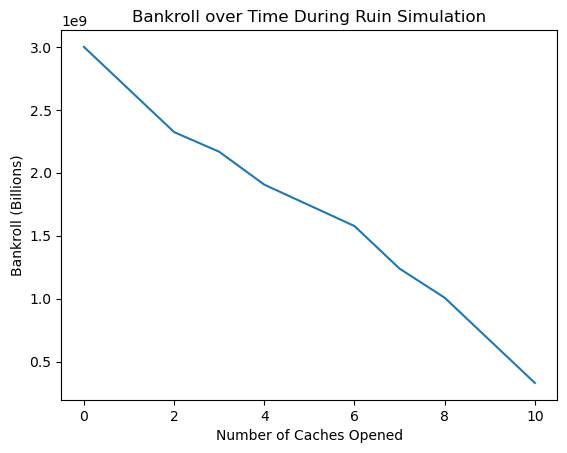

In [ ]:


_, steps = ruin(armorCache, initial_bankroll=3000000000, target=6000000000)
plt.plot(steps);
plt.title("Bankroll over Time During Ruin Simulation");
plt.xlabel("Number of Caches Opened");
plt.ylabel("Bankroll (Billions)");

In [145]:
def simulateTilEOD(armorCache, initial_bankroll=3000000000):
    bankroll = initial_bankroll
    final_steps = [bankroll]
    total_steps = 0
    while 0 < armorCache['cost'] < bankroll:
        profit, won, items = gamble(armorCache, times=1)
        total_steps += 1
        if any(item.startswith("EOD ") for item in items):
            final_steps.append(bankroll)
            return final_steps[-1], True, total_steps  # Return steps and items if EOD is found
        bankroll += profit
        final_steps.append(bankroll)
    return final_steps[-1], False, total_steps  # Return steps even if EOD is not found

def simulateLotsTilEOD(armorCache, trials=10000, initial_bankroll=3000000000):
    eod_found_count = 0
    final_step = []
    total_step = []
    failed_step = []
    total_step_failed = []
    for _ in range(trials):
        steps, eod_found, total_steps = simulateTilEOD(armorCache, initial_bankroll)
        if eod_found:
            eod_found_count += 1
            final_step.append(steps)
            total_step.append(total_steps)
        else:
            failed_step.append(steps)
            total_step_failed.append(total_steps)
    return final_step, eod_found_count, trials, total_step, total_step_failed, failed_step

In [146]:
final_price, eod_found_count, total_trials, total_step, total_step_failed, _ = simulateLotsTilEOD(armorCache)
print(f"After {total_trials} trials of opening Armor Caches until EOD is found")
print(f"EOD Found in {eod_found_count} trials ({eod_found_count/total_trials*100:.2f}%)")

After 10000 trials of opening Armor Caches until EOD is found
EOD Found in 1874 trials (18.74%)
